# CardioIA Fase 4 | Parte 1: pré-processamento das imagens

Prepara raios-X de tórax para classificar **cardiomegalia** (coração aumentado) contra **sem achado**.

Etapas: selecionar → dividir → baixar → pré-processar → conferir.

**Fonte:** [NIH Chest X-ray](https://nihcc.app.box.com/v/ChestXray-NIHCC), do NIH Clinical Center
(Wang et al., *ChestX-ray8*, CVPR 2017). O download usa um espelho no Hugging Face, porque ele
permite ler imagens avulsas de dentro dos zips, sem baixar os 45 GB.

In [1]:
import zipfile
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import fsspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from sklearn.model_selection import train_test_split

SEMENTE = 42
TAMANHO_FINAL = (224, 224)
QUANTIDADE_DE_ZIPS = 12

ESPELHO = "https://huggingface.co/datasets/alkzar90/NIH-Chest-X-ray-dataset/resolve/main/data"
URL_METADADOS = f"{ESPELHO}/Data_Entry_2017_v2020.csv"

esta_no_colab = Path("/content").exists()
PASTA_DADOS = Path("/content/dados") if esta_no_colab else Path("../dados")
PASTA_ORIGINAIS = PASTA_DADOS / "originais"
PASTA_PROCESSADOS = PASTA_DADOS / "processados"
PASTA_ORIGINAIS.mkdir(parents=True, exist_ok=True)
PASTA_PROCESSADOS.mkdir(parents=True, exist_ok=True)

## 1. Selecionar as imagens

In [2]:
metadados = pd.read_csv(URL_METADADOS).rename(
    columns={
        "Image Index": "arquivo",
        "Finding Labels": "achados",
        "Patient ID": "paciente",
        "Patient Age": "idade",
        "Patient Gender": "sexo",
        "View Position": "posicao",
    }
)
metadados["tem_cardiomegalia"] = metadados["achados"].str.split("|").apply(lambda achados: "Cardiomegaly" in achados)
metadados["sem_achado"] = metadados["achados"] == "No Finding"

print(f"Dataset completo: {len(metadados)} imagens de {metadados['paciente'].nunique()} pacientes")
print("Proporção de imagens AP em cada classe:")
print("  cardiomegalia:", round((metadados.loc[metadados["tem_cardiomegalia"], "posicao"] == "AP").mean(), 2))
print("  sem achado:   ", round((metadados.loc[metadados["sem_achado"], "posicao"] == "AP").mean(), 2))

Dataset completo: 112120 imagens de 30805 pacientes
Proporção de imagens AP em cada classe:
  cardiomegalia: 0.44
  sem achado:    0.35


O AP aumenta o coração na imagem e é mais comum na classe doente. Para a rede não aprender o tipo
de exame no lugar da doença, usamos **só PA** e **só adultos**.

Também usamos **uma imagem por paciente**: assim ninguém aparece em treino e teste ao mesmo tempo.

In [3]:
pacientes_com_cardiomegalia = set(metadados.loc[metadados["tem_cardiomegalia"], "paciente"])

eh_pa = metadados["posicao"] == "PA"
eh_adulto = metadados["idade"].between(18, 100)
nunca_teve_cardiomegalia = ~metadados["paciente"].isin(pacientes_com_cardiomegalia)

candidatas_cardiomegalia = metadados[eh_pa & eh_adulto & metadados["tem_cardiomegalia"]]
candidatas_sem_achado = metadados[eh_pa & eh_adulto & metadados["sem_achado"] & nunca_teve_cardiomegalia]


def uma_imagem_por_paciente(imagens):
    return imagens.groupby("paciente").sample(n=1, random_state=SEMENTE)


cardiomegalia = uma_imagem_por_paciente(candidatas_cardiomegalia).assign(classe="cardiomegalia")
sem_achado = (
    uma_imagem_por_paciente(candidatas_sem_achado)
    .sample(n=len(cardiomegalia), random_state=SEMENTE)
    .assign(classe="sem_achado")
)

selecao = pd.concat([cardiomegalia, sem_achado], ignore_index=True)
selecao = selecao[["arquivo", "classe", "paciente", "sexo", "idade"]]
print(selecao["classe"].value_counts().to_string())

classe
cardiomegalia    1117
sem_achado       1117


## 2. Dividir em treino, validação e teste (70 / 15 / 15)

In [4]:
treino, resto = train_test_split(selecao, test_size=0.30, stratify=selecao["classe"], random_state=SEMENTE)
validacao, teste = train_test_split(resto, test_size=0.50, stratify=resto["classe"], random_state=SEMENTE)

selecao = pd.concat(
    [
        treino.assign(conjunto="treino"),
        validacao.assign(conjunto="validacao"),
        teste.assign(conjunto="teste"),
    ],
    ignore_index=True,
)
selecao.to_csv(PASTA_PROCESSADOS / "selecao.csv", index=False)
print(pd.crosstab(selecao["conjunto"], selecao["classe"]).loc[["treino", "validacao", "teste"]])

classe     cardiomegalia  sem_achado
conjunto                            
treino               781         782
validacao            168         167
teste                168         168


## 3. Baixar só as imagens selecionadas

In [5]:
arquivos_desejados = set(selecao["arquivo"])


def baixar_imagens_do_zip(numero_do_zip):
    url_do_zip = f"{ESPELHO}/images/images_{numero_do_zip:03d}.zip"
    with fsspec.open(url_do_zip, "rb", block_size=2**20) as arquivo_remoto:
        zip_remoto = zipfile.ZipFile(arquivo_remoto)
        for caminho_no_zip in zip_remoto.namelist():
            nome = Path(caminho_no_zip).name
            destino = PASTA_ORIGINAIS / nome
            if nome in arquivos_desejados and not destino.exists():
                destino.write_bytes(zip_remoto.read(caminho_no_zip))


with ThreadPoolExecutor(max_workers=QUANTIDADE_DE_ZIPS) as baixadores:
    list(baixadores.map(baixar_imagens_do_zip, range(1, QUANTIDADE_DE_ZIPS + 1)))

arquivos_baixados = {caminho.name for caminho in PASTA_ORIGINAIS.glob("*.png")}
faltando = arquivos_desejados - arquivos_baixados
assert not faltando, f"{len(faltando)} imagens não foram baixadas"
tamanho_total_gb = sum((PASTA_ORIGINAIS / nome).stat().st_size for nome in arquivos_desejados) / 1e9
print(f"{len(arquivos_desejados)} imagens baixadas ({tamanho_total_gb:.2f} GB)")

2234 imagens baixadas (0.92 GB)


## 4. Pré-processar

1. **Converter o formato:** tudo para tons de cinza de 8 bits (algumas originais podem vir em RGBA).
2. **Normalizar o contraste:** algumas originais usam só parte dos tons de cinza. Esticamos todas
   para a faixa inteira (0 a 255), ignorando o 1% mais escuro e o 1% mais claro.
3. **Redimensionar:** de 1024×1024 para 224×224, o tamanho da VGG16 e da ResNet.

A escala dos pixels (0 a 255 → 0 a 1) fica **dentro do modelo**, porque a CNN do zero e as redes
pré-treinadas usam escalas diferentes.

In [6]:
formatos_originais = pd.Series([Image.open(PASTA_ORIGINAIS / nome).mode for nome in selecao["arquivo"]])
print("Formatos originais:", formatos_originais.value_counts().to_dict())


def preprocessar(imagem_original):
    em_cinza = imagem_original.convert("L")
    com_contraste = ImageOps.autocontrast(em_cinza, cutoff=1)
    return com_contraste.resize(TAMANHO_FINAL, Image.Resampling.LANCZOS)


for imagem in selecao.itertuples():
    pasta_de_destino = PASTA_PROCESSADOS / imagem.conjunto / imagem.classe
    pasta_de_destino.mkdir(parents=True, exist_ok=True)
    imagem_original = Image.open(PASTA_ORIGINAIS / imagem.arquivo)
    preprocessar(imagem_original).save(pasta_de_destino / imagem.arquivo)

Formatos originais: {'L': 2223, 'RGBA': 11}


## 5. Conferir o resultado

In [7]:
for conjunto in ["treino", "validacao", "teste"]:
    for classe in ["cardiomegalia", "sem_achado"]:
        esperado = len(selecao[(selecao["conjunto"] == conjunto) & (selecao["classe"] == classe)])
        encontrado = len(list((PASTA_PROCESSADOS / conjunto / classe).glob("*.png")))
        assert esperado == encontrado, f"{conjunto}/{classe}: esperado {esperado}, encontrado {encontrado}"
        print(f"{conjunto:10} {classe:14} {encontrado}")

assert selecao["paciente"].is_unique
print("Nenhum paciente se repete entre os conjuntos.")

treino     cardiomegalia  781
treino     sem_achado     782
validacao  cardiomegalia  168
validacao  sem_achado     167
teste      cardiomegalia  168
teste      sem_achado     168
Nenhum paciente se repete entre os conjuntos.


In [8]:
def caminho_processado(imagem):
    return PASTA_PROCESSADOS / imagem.conjunto / imagem.classe / imagem.arquivo


amostra = selecao[selecao["conjunto"] == "treino"].sample(n=200, random_state=SEMENTE)


def faixa_de_tons(imagem):
    tom_escuro, tom_claro = np.percentile(np.asarray(imagem.convert("L")), [1, 99])
    return tom_claro - tom_escuro


faixas_antes = [faixa_de_tons(Image.open(PASTA_ORIGINAIS / imagem.arquivo)) for imagem in amostra.itertuples()]
faixas_depois = [faixa_de_tons(Image.open(caminho_processado(imagem))) for imagem in amostra.itertuples()]
print(f"Faixa de tons usada, antes:  {np.mean(faixas_antes):.0f} ± {np.std(faixas_antes):.0f} (mínimo {np.min(faixas_antes):.0f})")
print(f"Faixa de tons usada, depois: {np.mean(faixas_depois):.0f} ± {np.std(faixas_depois):.0f} (mínimo {np.min(faixas_depois):.0f})")

Faixa de tons usada, antes:  220 ± 27 (mínimo 134)
Faixa de tons usada, depois: 253 ± 1 (mínimo 249)


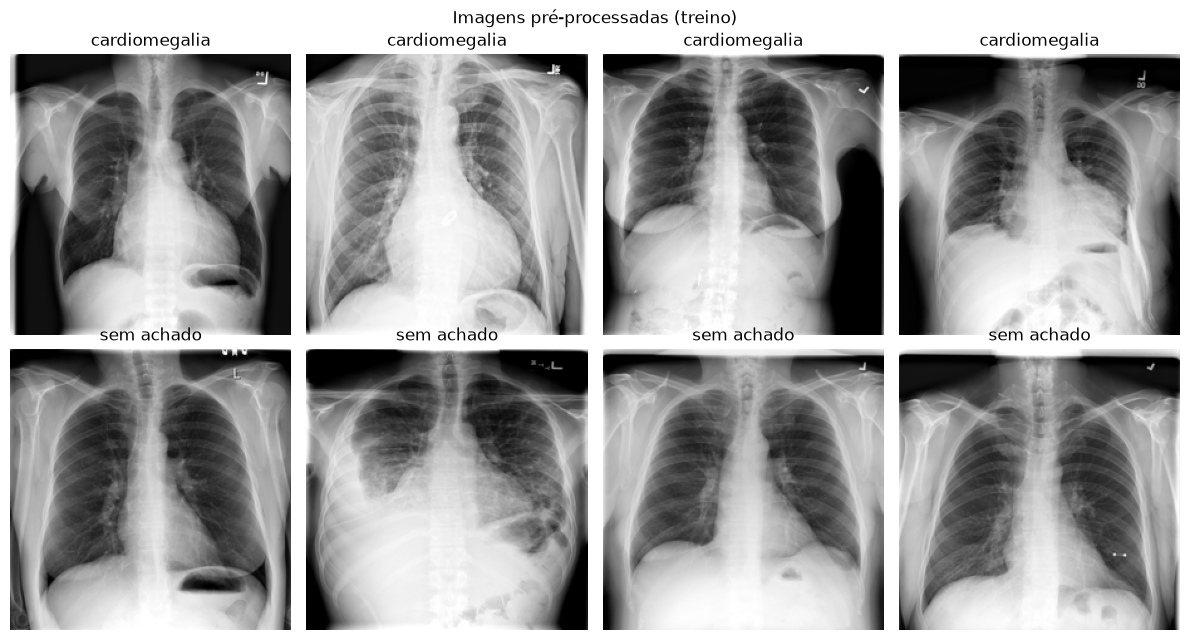

In [9]:
figura, eixos = plt.subplots(2, 4, figsize=(12, 6.5))
for linha, classe in enumerate(["cardiomegalia", "sem_achado"]):
    exemplos = selecao[(selecao["conjunto"] == "treino") & (selecao["classe"] == classe)].head(4)
    for eixo, imagem in zip(eixos[linha], exemplos.itertuples()):
        eixo.imshow(Image.open(caminho_processado(imagem)), cmap="gray")
        eixo.set_title(classe.replace("_", " "))
        eixo.axis("off")
figura.suptitle("Imagens pré-processadas (treino)")
figura.tight_layout()
figura.savefig("exemplos_preprocessados.png", dpi=110)
plt.show()

## Perfil dos pacientes em cada classe

In [10]:
perfil = selecao.groupby("classe").agg(
    imagens=("arquivo", "count"),
    idade_media=("idade", "mean"),
    percentual_mulheres=("sexo", lambda sexo: 100 * (sexo == "F").mean()),
)
print(perfil.round(1))

               imagens  idade_media  percentual_mulheres
classe                                                  
cardiomegalia     1117         51.4                 56.8
sem_achado        1117         46.2                 46.6
